151.99731779103058
9.259344437543701


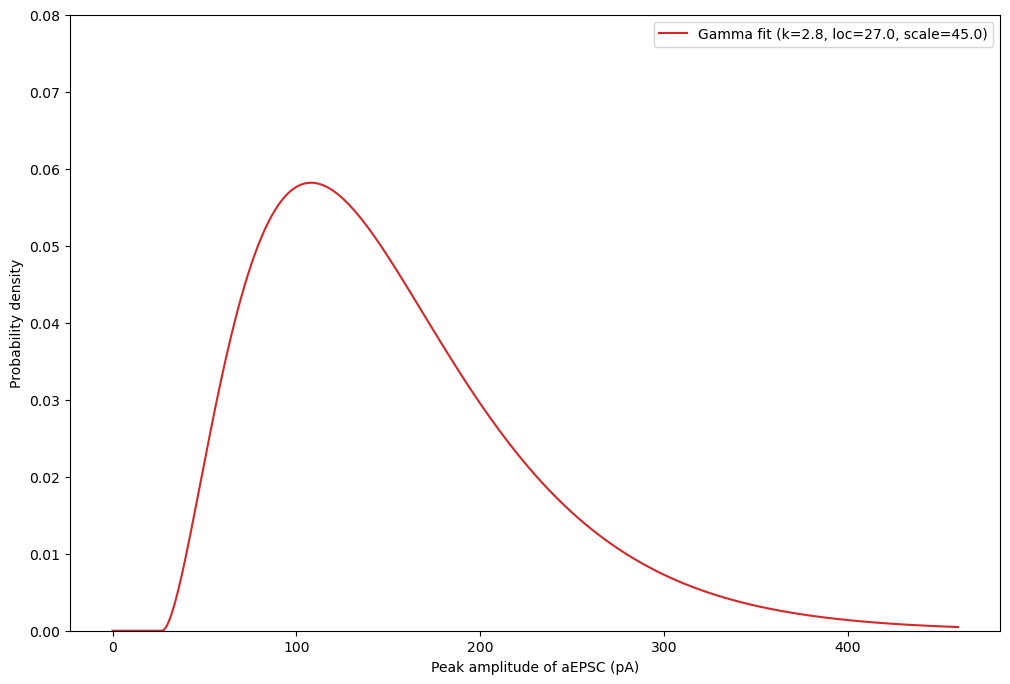

In [27]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gamma

def weighted_avg_and_std(values, weights):
    """
    Return the weighted average and standard deviation.

    They weights are in effect first normalized so that they 
    sum to 1 (and so they must not all be 0).

    values, weights -- NumPy ndarrays with the same shape.
    """
    average = np.average(values, weights=weights)
    # Fast and numerically precise:
    variance = np.average((values-average)**2, weights=weights)
    return (average, np.sqrt(variance))


# Estimated parameters (Shifted Gamma)
shape = 2.8     # 2.5 - 3.0
loc = 27.0      # 
scale = 45.0    # 35 - 45

# Generate distribution curve
x = np.linspace(0, 460, 500)
x_width = x[1] - x[0]
pdf = gamma.pdf(x, a=shape, loc=loc, scale=scale) * 10 * x_width 

avg, std = weighted_avg_and_std(x, pdf)
print(avg)

print(std/np.sqrt(62))

# Plot comparison
fig, ax = plt.subplots(1, 1, figsize = (12, 8))
ax.plot(x, pdf, label=f"Gamma fit (k={shape}, loc={loc}, scale={scale})", color="tab:red")
ax.set_xlabel("Peak amplitude of aEPSC (pA)")
ax.set_ylabel("Probability density")
ax.set_ylim(0, 0.08)
ax.legend()

plt.savefig(f'./random_plots/peak_autapse_distribution.svg')